# Promoter Panel Selection — Earlier Method (Annotated Copy)

This is an annotated copy of `findingPromoters.ipynb` (original left untouched). **Note:** this notebook represents an earlier promoter-selection approach (median expression + quantile sampling), later superseded by the expression-stability-Score and AlphaFold-annotation-filtered approach in `newsamplingmethod.ipynb`. Kept here for record; markdown notes explain each step and a summary funnel graph is appended at the end.

## Step 1 — Load RNA-seq data, compute a simple median-expression score
Earlier/simpler method (superseded by `newsamplingmethod.ipynb`). Loads normalized RNA-seq data and takes each gene's median expression across the 10 biological samples.

In [1]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
import numpy as np
import matplotlib.transforms as transforms
from Bio import SeqIO
from Bio.SeqRecord import SeqRecord
from Bio.Seq import Seq
import matplotlib.colors as mcolors
from matplotlib_venn import venn3
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
import matplotlib as mpl
import gzip

#Import the normalized RNA-seq data
norm_data = pd.read_csv('2025-05-19_24TG06_vsd_Rp.csv.gz', compression='gzip', header=0, usecols=range(11))

df = pd.DataFrame(norm_data)
cols = df.columns[1:]
#Determine the median expression level across all 10 biological samples per gene
df['median'] = df[cols].median(axis=1)

Top 100 genes by median expression (quick look, not used further downstream).

In [2]:
top_genes = (df.nlargest(100,'median').iloc[:,[0,df.columns.get_loc('median')]])

## Step 2 — Restrict to well-annotated genes, then quantile-sample 12
Loads `braker_metadata.xlsx`, counts how many of its 6 annotation fields are filled in per gene, and keeps only genes with ≥5/6 annotations present. Those annotated genes are then intersected with the RNA-seq set, split into 12 expression quantiles, and one gene is randomly sampled per quantile — the resulting `promoter_set` is this method's 12-gene panel.

In [3]:
#Import the annotations
meta = pd.read_excel("braker_metadata.xlsx", header=0)
#Gene ID
gene_col_meta = meta.columns[1]
#Annotations
annot_cols = meta.columns[3:9]
meta["n_annotations"] = (meta[annot_cols] != "-").sum(axis=1)
#Selecting for genes that have 5 or 6 annotations only
annotated_genes = meta.loc[
    meta["n_annotations"] >= 5,
    gene_col_meta
]
gene_col_df = df.columns[0]
expr_col = "median"
df_filt = df[df[gene_col_df].isin(annotated_genes)].copy()

N = 12
#splitting the genes into 12 quantiles
df_filt["_bin"] = pd.qcut(
    df_filt[expr_col],
    q=N,
    labels=False,
    duplicates="drop"
)
#Sampling one gene per quantile
promoter_set = (
    df_filt
    .groupby("_bin", group_keys=False)
    .sample(n=1, random_state=6769)
    [[gene_col_df, expr_col]]
    .rename(columns={gene_col_df: "gene_id", expr_col: "expr"})
    .sort_values("expr")
    .reset_index(drop=True)
)

df_filt.drop(columns="_bin", inplace=True)

## Step 3 — Extract protein sequences for the selected genes
Pulls protein FASTA sequences for the 12 selected genes from the BRAKER proteome.

In [4]:
#import braker files to search for protein sequence
input_fasta = "braker.faa.gz"
output_fasta = "promoter_genes.fa"

# Convert gene IDs to a set of strings for fast lookup
gene_ids = set(promoter_set['gene_id'].astype(str))

with gzip.open(input_fasta, "rt") as handle, open(output_fasta, "w") as out:
    for record in SeqIO.parse(handle, "fasta"):
        # Remove .t1 or .t2 suffix from BRAKER IDs
        if record.id.endswith(".t1") and record.id.split(".")[0] in gene_ids:
            SeqIO.write(record, out, "fasta")

print(f"Done! Wrote protein sequences for {len(gene_ids)} genes.")

Done! Wrote protein sequences for 12 genes.


In [5]:
#promoter_set.to_excel("promoter_set.xlsx")

## Step 4 — Extract CDS nucleotide sequences
Pulls the first-isoform CDS sequence per selected gene from the assembly CDS FASTA.

In [6]:
#import fasta files to search for nucleotide sequence
input_nuc = "assembly_cds.fasta"
output_nuc = "promoter_set_cds.fasta"

seen_genes = set()

with open(output_nuc, "w") as out_fh:
    for record in SeqIO.parse(input_nuc, "fasta"):
        # parse header fields
        fields = {
            f.split("=")[0]: f.split("=")[1]
            for f in record.id.split(";")
            if "=" in f
        }

        gene = fields.get("Parent")   # gene-level ID (e.g. g1)

        # keep only first isoform per gene
        if gene in gene_ids and gene not in seen_genes:
            SeqIO.write(record, out_fh, "fasta")
            seen_genes.add(gene)



The Proteome number for R microsporus is STRG0A18OCV.
When searching on String db, use organims id "Rhizopus microsporus ATCC 52813".

## Step 5 — Extract 1000 bp upstream promoter regions
Uses BLAST coordinates of each CDS against the genome to pull the upstream promoter sequence for each selected gene, respecting strand.

In [7]:
# Load BLAST results
cols = ["qseqid", "contig", "start", "end", "strand", "pident", "length"]
blast = pd.read_csv("cds_vs_genome.tsv", sep="\t", names=cols)

# Load genome into dictionary
genome = SeqIO.to_dict(SeqIO.parse("assembly.fasta", "fasta"))

PROMOTER_LEN = 1000
records = []

for _, row in blast.iterrows():
    gene = row.qseqid
    contig = row.contig
    start = int(row.start)
    end = int(row.end)
    strand = row.strand

    seq = genome[contig].seq

    if strand == "plus":
        prom_start = max(0, min(start, end) - PROMOTER_LEN - 1)
        prom_end = min(start, end) - 1
        promoter = seq[prom_start:prom_end]

    elif strand == "minus":
        prom_start = max(start, end)
        prom_end = min(len(seq), prom_start + PROMOTER_LEN)
        promoter = seq[prom_start:prom_end].reverse_complement()

    else:
        continue

    records.append(
        SeqIO.SeqRecord(
            promoter,
            id=f"{gene}_promoter",
            description=""
        )
    )

# Write promoter FASTA
SeqIO.write(records, "promoter_set_500bp.fasta", "fasta")

13

## Step 6 — Write Primer3 input for primer design

In [8]:
with open("primer3_input.txt", "w") as out:
    for record in SeqIO.parse("promoter_set_500bp.fasta", "fasta"):
        out.write(f"""SEQUENCE_ID={record.id}
SEQUENCE_TEMPLATE={str(record.seq)}
PRIMER_TASK=generic
PRIMER_PICK_LEFT_PRIMER=1
PRIMER_PICK_RIGHT_PRIMER=1
PRIMER_OPT_SIZE=22
PRIMER_MIN_SIZE=20
PRIMER_MAX_SIZE=25
PRIMER_OPT_TM=60.0
PRIMER_MIN_TM=58.0
PRIMER_MAX_TM=62.0
PRIMER_PRODUCT_SIZE_RANGE=200-500
=
""")

## Step 7 — Parse Primer3 output back into a table

In [9]:
records_parse = []
current_parse = {}

with open("primer3_output.txt") as f:
    for line in f:
        line = line.strip()

        if not line:
            continue

        if line == "=":
            if "SEQUENCE_ID" in current_parse:
                records_parse.append(current_parse)
            current_parse = {}
            continue

        if "=" in line:
            key, value = line.split("=", 1)
            current_parse[key] = value

# Convert to DataFrame
df_parse = pd.DataFrame(records_parse)

# Keep only useful columns (if present)
cols = [
    "SEQUENCE_ID",
    "PRIMER_LEFT_0_SEQUENCE",
    "PRIMER_RIGHT_0_SEQUENCE",
    "PRIMER_LEFT_0_TM",
    "PRIMER_RIGHT_0_TM",
    "PRIMER_LEFT_0_GC_PERCENT",
    "PRIMER_RIGHT_0_GC_PERCENT",
    "PRIMER_PRODUCT_SIZE"
]

df_parse = df_parse[[c for c in cols if c in df_parse.columns]]

## Step 8 — Assemble the final export table
Merges the selected gene set with BRAKER descriptions, BLAST contig/length info, and STRING preferred names into one export table.

In [10]:
#Export Table:

export_df = pd.DataFrame(promoter_set)

braker_mapping = meta.iloc[:,[1,4]].copy()
braker_mapping.columns = ["gene_id", "braker_description"]
export_df["gene_id"] = export_df["gene_id"].astype(str)
braker_mapping["gene_id"] = braker_mapping["gene_id"].astype(str)
export_df = export_df.merge(
    braker_mapping,
    on="gene_id",
    how="left"
)
export_df = export_df.drop_duplicates(subset="gene_id")
blast["parent_gene_id"] = (
    blast["qseqid"]
    .str.split("Parent=")
    .str[1]
    .str.split(";")
    .str[0]
)
blast_gene = (
    blast[["parent_gene_id", "contig", "length"]]
    .drop_duplicates("parent_gene_id")
    .set_index("parent_gene_id")
)

export_df = export_df.merge(
    blast_gene,
    left_on="gene_id",
    right_on="parent_gene_id",
    how="left"
)

string_mapping = pd.read_csv("string_mapping_6769.tsv", sep='\t', header=0)

export_df["preferredName"]=string_mapping['preferredName']

cols_export = export_df.columns.tolist()
export_df = export_df[[cols_export[5]] + cols_export[:5] + cols_export[6:]]

In [11]:
promoter_set.to_csv("promoter_set.csv")  # fixed: was pd.to_csv(promoter_set, ...) in original, which errors

---
# Summary graph: gene counts through this earlier selection funnel

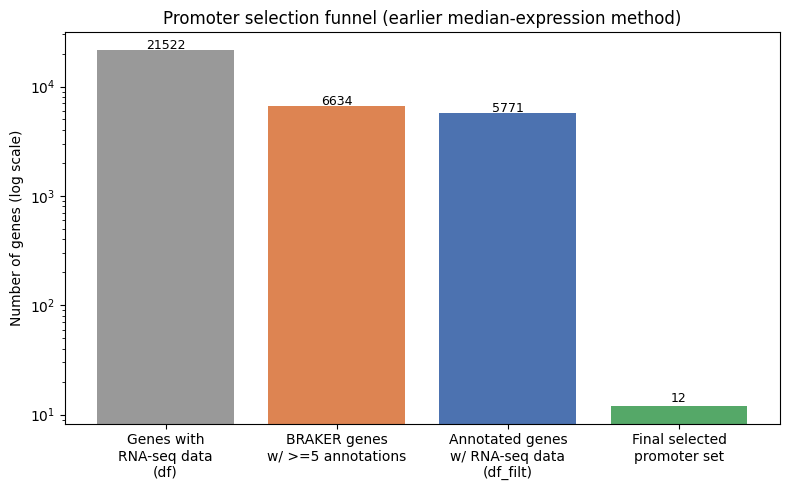

In [12]:
import matplotlib.pyplot as plt

stages = ['Genes with\nRNA-seq data\n(df)', 'BRAKER genes\nw/ >=5 annotations', 'Annotated genes\nw/ RNA-seq data\n(df_filt)', 'Final selected\npromoter set']
counts = [len(df), len(annotated_genes), len(df_filt), len(promoter_set)]

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(stages, counts, color=['#999999', '#DD8452', '#4C72B0', '#55A868'])
for b, v in zip(bars, counts):
    ax.text(b.get_x()+b.get_width()/2, v*1.02 if v>50 else v+1, f'{v}', ha='center', fontsize=9)
ax.set_yscale('log')
ax.set_ylabel('Number of genes (log scale)')
ax.set_title('Promoter selection funnel (earlier median-expression method)')
plt.tight_layout()
plt.savefig('promoter_selection_funnel_v1.png', dpi=150)
plt.show()